In [1]:
import sys
print(sys.executable)

d:\SkillPathAI\.venv\Scripts\python.exe


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
from pathlib import Path

DATA_PATH = Path("../data/processed/career_dataset_normalized.csv")

career_df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", career_df.shape)

Dataset loaded successfully!
Dataset shape: (9000, 16)


In [4]:
print("First 5 records:")
display(career_df.head())

print("\nDataset information:")
career_df.info()

print("\nColumn names:")
print(career_df.columns.tolist())

First 5 records:


,Education Level,Specialization,Skills,Certifications,CGPA/Percentage,Recommended Career,Certification_Status,Score_Type,Score_Value,Technical_Skills_Parsed,Soft_Skills_Parsed,Skills_Gained_Parsed,Technical_Skill_Count,Soft_Skill_Count,Skills_Gained_Count,Recommended_Career_Original
0,BA,Agriculture,Technical: Microsoft Excel; Python; Data analy...,Not specified,8.22,M.Sc Biotechnology / Microbiology / Life Sciences,Not specified,CGPA,8.22,Microsoft Excel; Python; Data analysis; Biolog...,Critical thinking; Problem-solving,Research methods; Data analysis; Biology funda...,4,2,5,M.Sc Biotechnology / Microbiology / Life Sciences
1,Class 10,Not yet selected,Technical: Digital creativity; Visual storytel...,Introductory online course,56.00,Arts / Humanities or a relevant design-oriente...,Provided,Percentage,56.00,Digital creativity; Visual storytelling,Research; Communication,Design fundamentals; Drawing,2,2,2,Arts / Humanities or a relevant design-oriente...
2,Class 10,Not yet selected,Technical: Subject knowledge; Presentation | S...,Introductory online course,84.50,Choose a suitable stream based on preferred te...,Provided,Percentage,84.50,Subject knowledge; Presentation,Patience; Empathy; Adaptability,Subject knowledge; Communication,2,3,2,Choose a suitable stream based on preferred te...
3,Class 12,CEC,Technical: Planning; Excel basics | Soft: Rese...,Basic computer course,40.80,B.Com / BBA / B.A. Economics,Provided,Percentage,40.80,Planning; Excel basics,Research; Teamwork; Presentation; Leadership,Planning; Presentation; Business communication,2,4,3,B.Com / BBA / B.A. Economics
4,B.Des,Pharmacy,Technical: Environmental awareness; Python; Ob...,SWAYAM certificate,7.27,M.Sc Agriculture / Horticulture / Food Science...,Provided,CGPA,7.27,Environmental awareness; Python; Observation; ...,Research; Presentation; Adaptability; Leadership,Data recording; Data analysis; Environmental a...,5,4,4,M.Sc Agriculture / Horticulture / Food Science...



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 9000 entries, 0 to 8999
Data columns (total 16 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Education Level              9000 non-null   str    
 1   Specialization               9000 non-null   str    
 2   Skills                       9000 non-null   str    
 3   Certifications               9000 non-null   str    
 4   CGPA/Percentage              9000 non-null   float64
 5   Recommended Career           9000 non-null   str    
 6   Certification_Status         9000 non-null   str    
 7   Score_Type                   9000 non-null   str    
 8   Score_Value                  9000 non-null   float64
 9   Technical_Skills_Parsed      9000 non-null   str    
 10  Soft_Skills_Parsed           9000 non-null   str    
 11  Skills_Gained_Parsed         9000 non-null   str    
 12  Technical_Skill_Count        9000 non-null   int64  
 13  Soft_Sk

In [5]:
# Count missing values in each column
missing_values = career_df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing_Values": missing_values,
    "Missing_Percentage": (missing_values / len(career_df)) * 100
})

display(missing_summary)

,Missing_Values,Missing_Percentage
Education Level,0,0.0
Specialization,0,0.0
Skills,0,0.0
Certifications,0,0.0
CGPA/Percentage,0,0.0
Recommended Career,0,0.0
Certification_Status,0,0.0
Score_Type,0,0.0
Score_Value,0,0.0
Technical_Skills_Parsed,0,0.0


In [6]:
empty_values = career_df.select_dtypes(include=["object", "str"]).apply(
    lambda column: column.str.strip().eq("").sum()
)

print("Empty or blank values:")
display(empty_values)

Empty or blank values:


Education Level                0
Specialization                 0
Skills                         0
Certifications                 0
Recommended Career             0
Certification_Status           0
Score_Type                     0
Technical_Skills_Parsed        0
Soft_Skills_Parsed             0
Skills_Gained_Parsed           0
Recommended_Career_Original    0
dtype: int64

Education Level Distribution:


Education Level
Class 10    3000
Class 12    3000
BA           363
BBA          354
B.Des        351
B.Pharm      337
B.Sc         329
B.Ag         320
B.Com        320
B.Tech       313
BCA          313
Name: count, dtype: int64

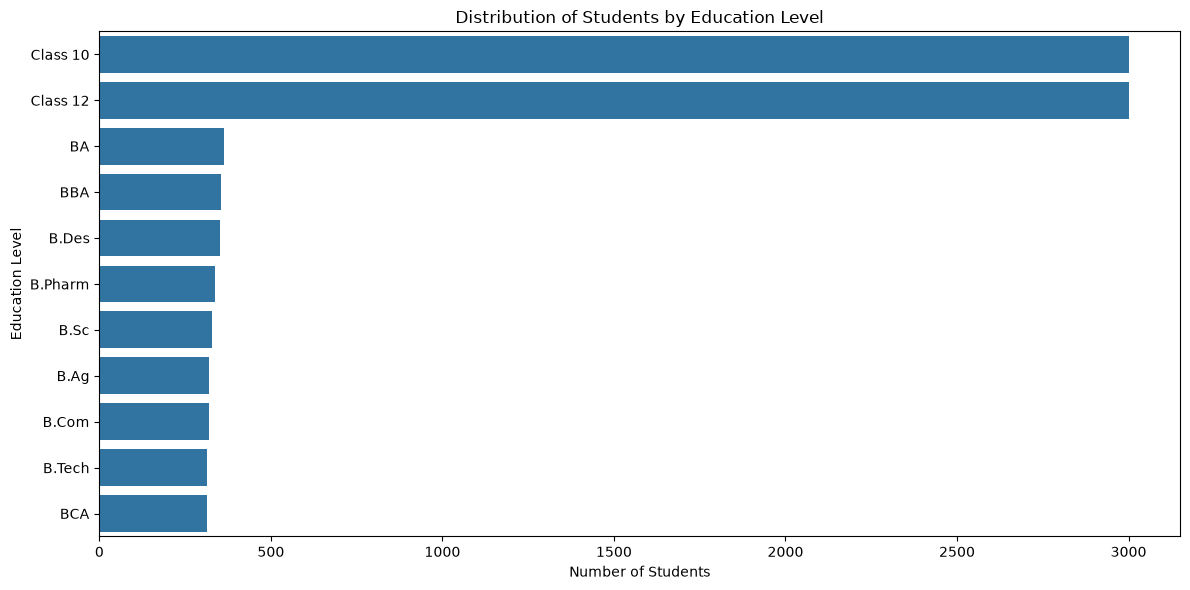

In [7]:
education_counts = career_df["Education Level"].value_counts()

print("Education Level Distribution:")
display(education_counts)

plt.figure(figsize=(12, 6))

sns.countplot(
    data=career_df,
    y="Education Level",
    order=education_counts.index
)

plt.title("Distribution of Students by Education Level")
plt.xlabel("Number of Students")
plt.ylabel("Education Level")
plt.tight_layout()
plt.show()

Specialization Distribution:


Specialization
Not yet selected         3000
BiPC                      993
MPC                       790
Agriculture               416
Commerce                  399
Pharmacy                  389
CEC                       378
Science                   371
Design                    366
Arts/Humanities           363
Engineering               349
Computer Applications     347
MEC                       308
HEC / Humanities          271
Humanities                163
Arts                       97
Name: count, dtype: int64

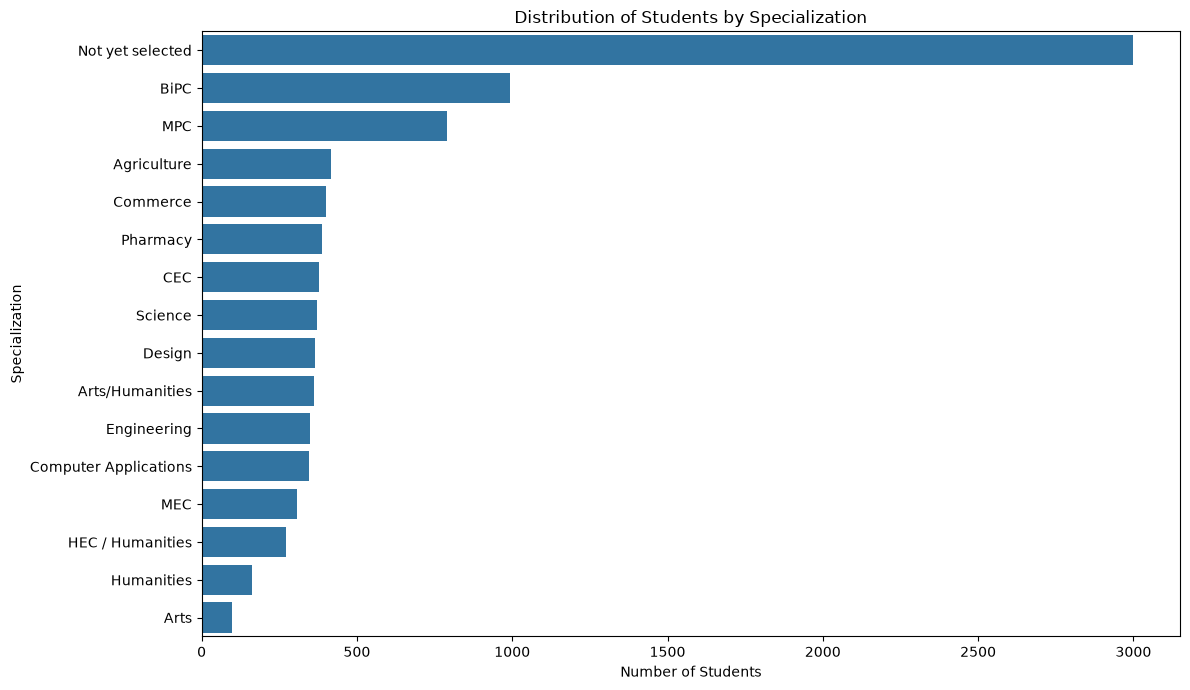

In [8]:
specialization_counts = career_df["Specialization"].value_counts()

print("Specialization Distribution:")
display(specialization_counts)

plt.figure(figsize=(12, 7))

sns.countplot(
    data=career_df,
    y="Specialization",
    order=specialization_counts.index
)

plt.title("Distribution of Students by Specialization")
plt.xlabel("Number of Students")
plt.ylabel("Specialization")
plt.tight_layout()
plt.show()

Top 15 Recommended Careers:


Recommended Career
M.Sc / postgraduate specialization in a relevant life-science or healthcare field    351
BiPC → Intermediate (BiPC) → Healthcare-related degree pathway                       336
B.Sc Biotechnology / Microbiology / Life Sciences                                    329
B.Com / BBA / B.A. Economics                                                         314
MBBS / BDS / B.Pharm / B.Sc Nursing (subject to eligibility)                         313
M.Tech Computer Science / M.S. in Computer Science                                   312
CEC / MEC → Intermediate → B.Com / Finance pathway                                   310
MPC → Intermediate (MPC) → B.Tech Computer Science and Engineering                   309
B.Des / BFA / BA in Media and Communication (subject to eligibility)                 305
Arts / Humanities or a relevant design-oriented vocational pathway                   304
B.Tech Mechanical / Electrical / Civil Engineering                                   304
M.

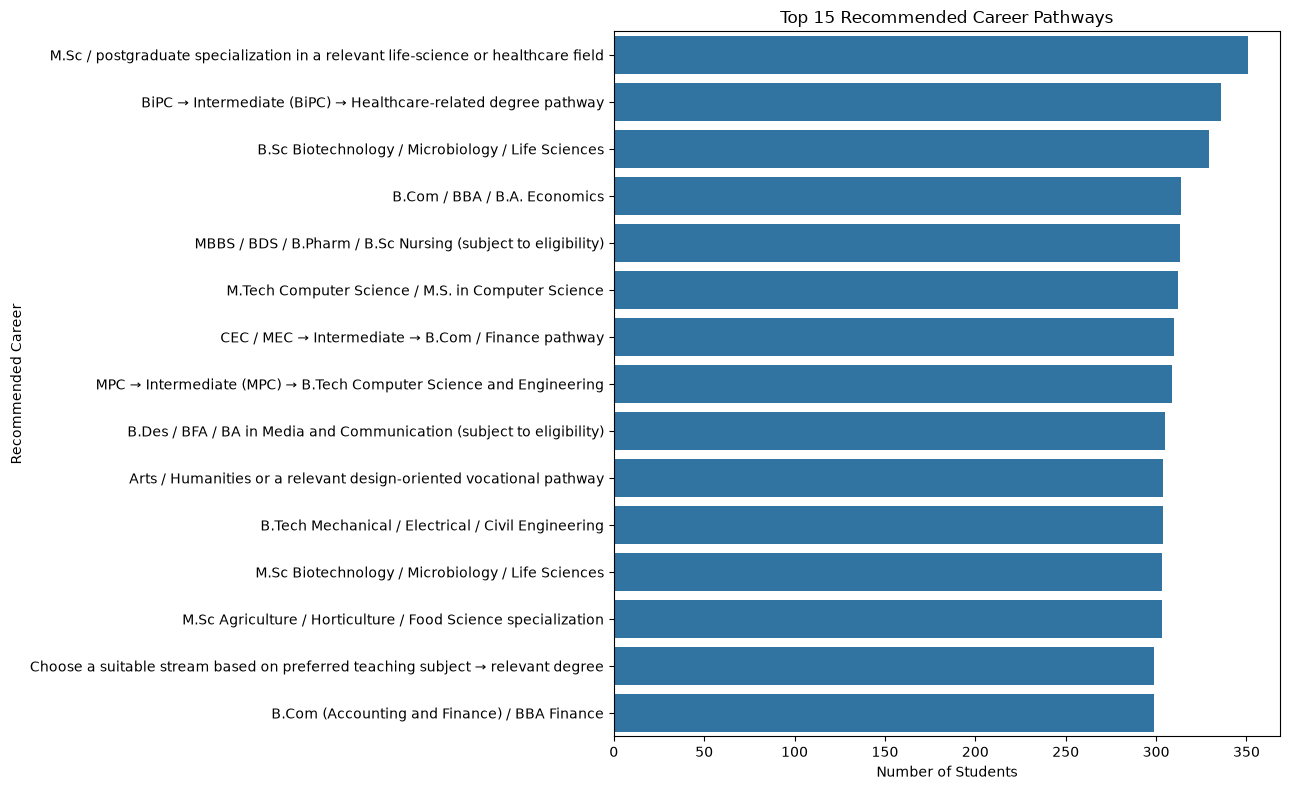

In [9]:
career_counts = career_df["Recommended Career"].value_counts()

print("Top 15 Recommended Careers:")
display(career_counts.head(15))

plt.figure(figsize=(13, 8))

sns.countplot(
    data=career_df,
    y="Recommended Career",
    order=career_counts.head(15).index
)

plt.title("Top 15 Recommended Career Pathways")
plt.xlabel("Number of Students")
plt.ylabel("Recommended Career")
plt.tight_layout()
plt.show()

In [10]:
# Separate scores by type
percentage_scores = career_df[
    career_df["Score_Type"] == "Percentage"
]["Score_Value"]

cgpa_scores = career_df[
    career_df["Score_Type"] == "CGPA"
]["Score_Value"]

print("Percentage Statistics:")
display(percentage_scores.describe())

print("\nCGPA Statistics:")
display(cgpa_scores.describe())

Percentage Statistics:


count    6000.000000
mean       76.833917
std        11.317694
min        37.900000
25%        69.200000
50%        77.100000
75%        84.600000
max        99.500000
Name: Score_Value, dtype: float64


CGPA Statistics:


count    3000.000000
mean        7.602030
std         0.870179
min         4.340000
25%         7.010000
50%         7.590000
75%         8.200000
max        10.000000
Name: Score_Value, dtype: float64

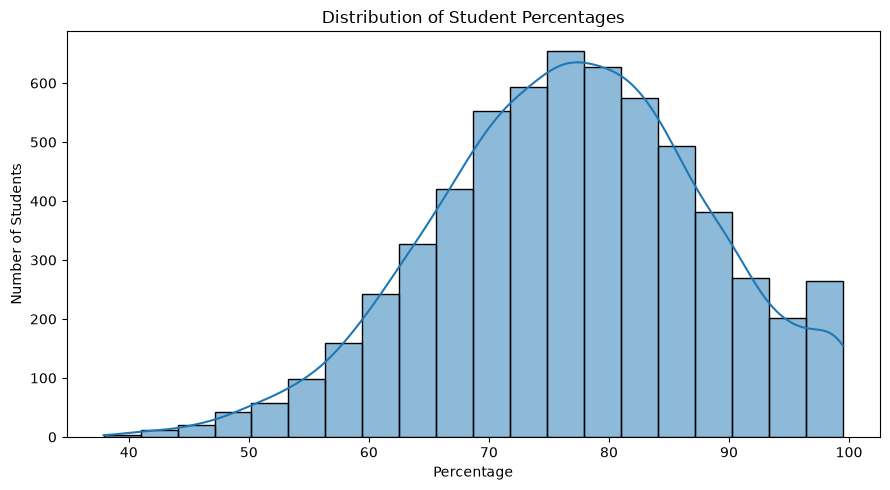

In [11]:
# Percentage distribution
plt.figure(figsize=(9, 5))

sns.histplot(percentage_scores, bins=20, kde=True)

plt.title("Distribution of Student Percentages")
plt.xlabel("Percentage")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

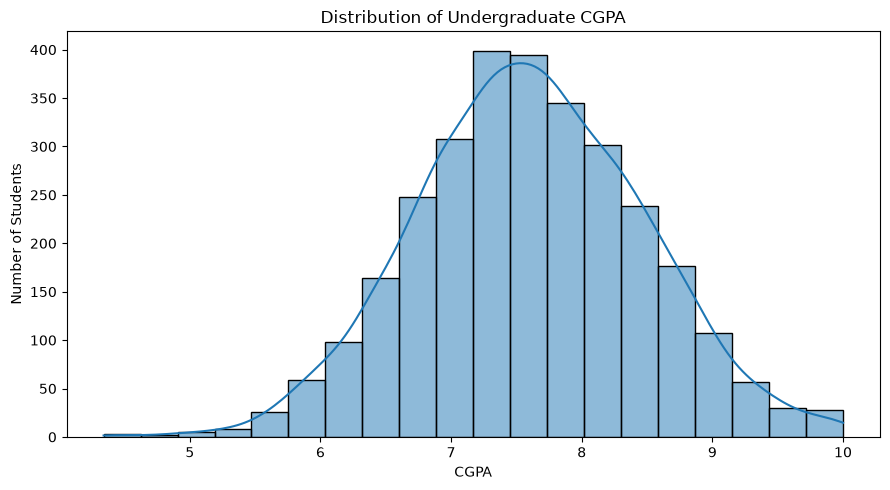

In [12]:
# CGPA distribution
plt.figure(figsize=(9, 5))

sns.histplot(cgpa_scores, bins=20, kde=True)

plt.title("Distribution of Undergraduate CGPA")
plt.xlabel("CGPA")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

In [8]:
from collections import Counter

# Define technical skills to retain
technical_skill_keywords = {
    "python",
    "sql",
    "sql basics",
    "microsoft excel",
    "excel",
    "data analysis",
    "data analytics",
    "machine learning",
    "deep learning",
    "artificial intelligence",
    "power bi",
    "tableau",
    "numpy",
    "pandas",
    "matplotlib",
    "seaborn",
    "scikit-learn",
    "java",
    "c",
    "c++",
    "html",
    "css",
    "javascript",
    "react",
    "node.js",
    "mysql",
    "postgresql",
    "mongodb",
    "statistics",
    "data visualization",
    "web development",
    "cloud computing",
    "aws",
    "azure",
    "git",
    "linux",
    "cybersecurity"
}

technical_skills = career_df["Technical_Skills_Parsed"].dropna()

technical_skill_list = []

for skills in technical_skills:
    for skill in skills.split(";"):
        skill = skill.strip()
        
        if skill.lower() in technical_skill_keywords:
            technical_skill_list.append(skill)

# Count technical skills
technical_skill_counts = Counter(technical_skill_list)

top_technical_skills = pd.Series(
    technical_skill_counts
).sort_values(ascending=False).head(15)

print("Top 5 Technical Skills:")
display(top_technical_skills)


Top 5 Technical Skills:


Python             1202
Data analysis      1158
SQL basics         1154
Microsoft Excel    1116
Excel               459
dtype: int64

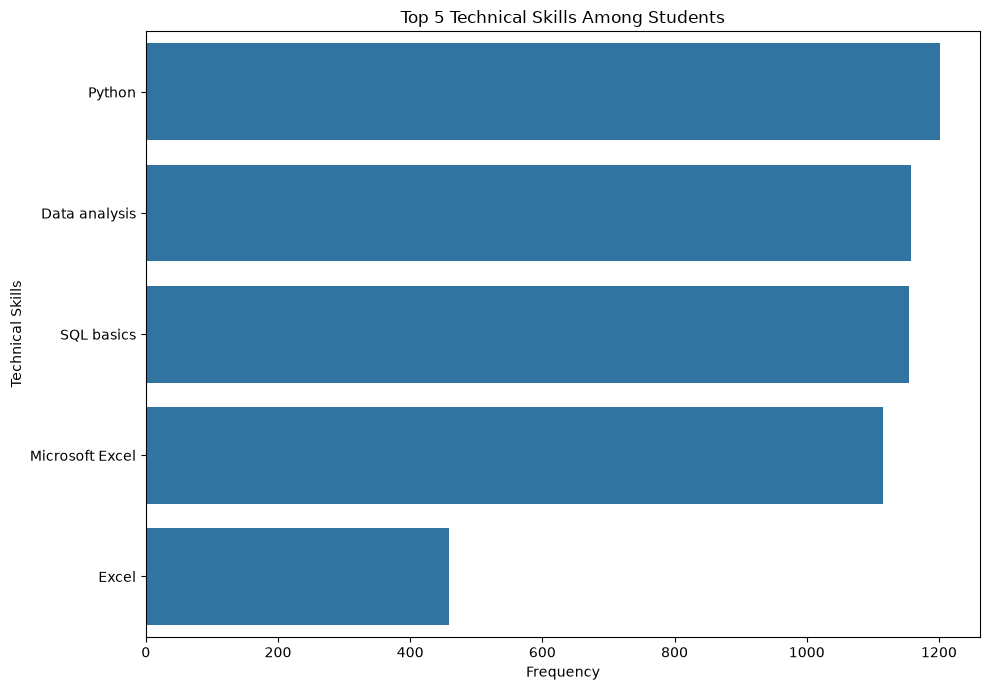

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 7))

sns.barplot(
    x=top_technical_skills.values,
    y=top_technical_skills.index
)

plt.title("Top 5 Technical Skills Among Students")
plt.xlabel("Frequency")
plt.ylabel("Technical Skills")

plt.tight_layout()
plt.show()

In [14]:
soft_skill_list = []

for skills in career_df["Soft_Skills_Parsed"].dropna():
    soft_skill_list.extend(
        [skill.strip() for skill in skills.split(";") if skill.strip()]
    )

soft_skill_counts = Counter(soft_skill_list)

top_soft_skills = pd.Series(
    soft_skill_counts
).sort_values(ascending=False).head(15)

print("Top Soft Skills:")
display(top_soft_skills)

Top Soft Skills:


Communication          2890
Critical thinking      2788
Adaptability           2653
Teamwork               2633
Problem-solving        2544
Leadership             2295
Research               2251
Creativity             2223
Presentation           2106
Time management        2052
Attention to detail     644
Empathy                 611
Analytical thinking     217
Integrity               208
Patience                196
dtype: int64

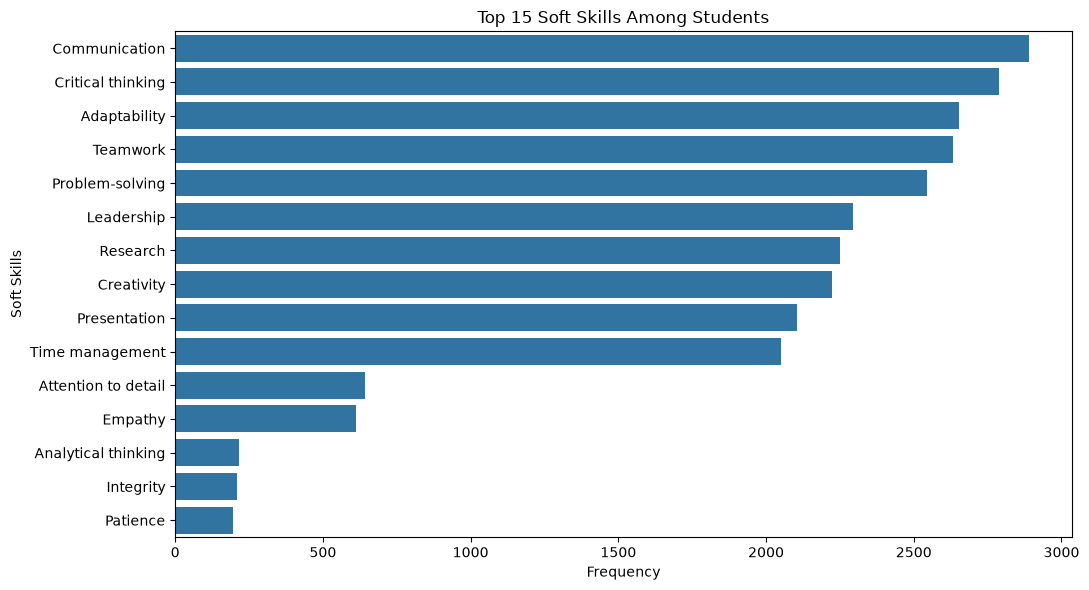

In [17]:
plt.figure(figsize=(11, 6))

sns.barplot(
    x=top_soft_skills.values,
    y=top_soft_skills.index
)

plt.title("Top 15 Soft Skills Among Students")
plt.xlabel("Frequency")
plt.ylabel("Soft Skills")
plt.tight_layout()
plt.show()

In [14]:
certification_counts = career_df["Certifications"].value_counts()

certification_counts = certification_counts[
    certification_counts.index != "Not specified"
]

print("Top 15 Certifications:")
display(certification_counts.head(15))

Top 15 Certifications:


Certifications
Basic computer course              1445
Subject-related certificate         761
Introductory online course          755
Online introductory certificate     748
School-level STEM certificate       745
Industry-oriented certificate       621
SWAYAM certificate                  615
Coursera certificate                586
NPTEL course certificate            573
Name: count, dtype: int64

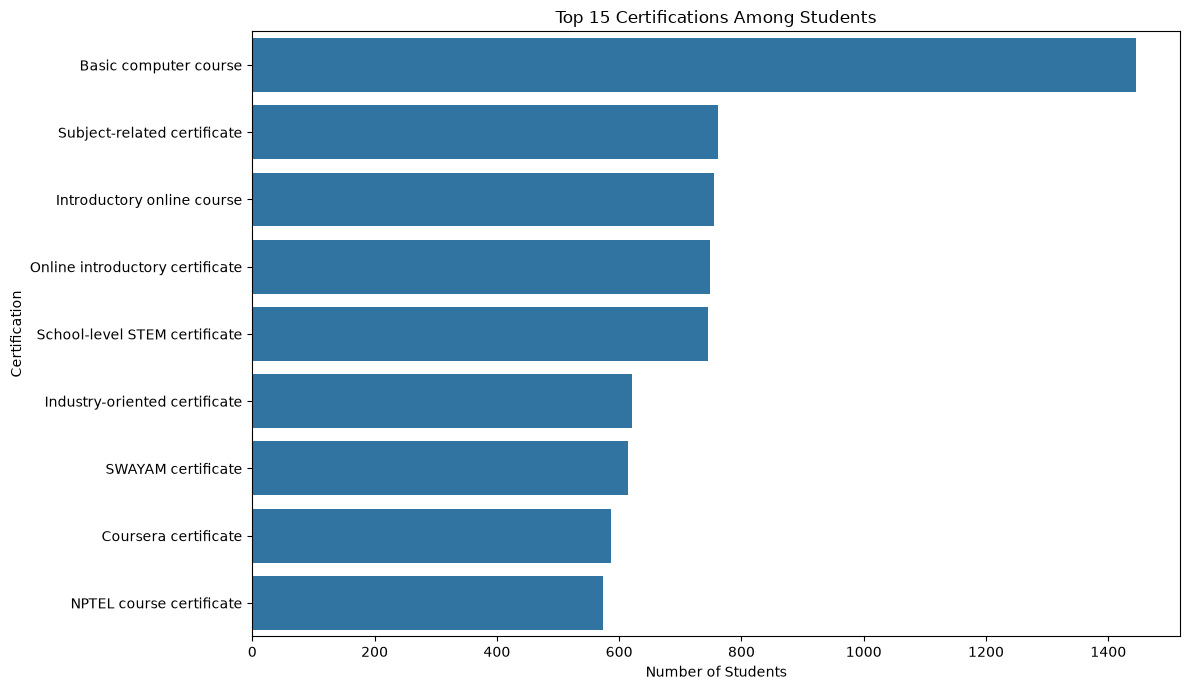

In [15]:
plt.figure(figsize=(12, 7))

top_certifications = certification_counts[
    certification_counts.index != "Not specified"
].head(15)

sns.barplot(
    x=top_certifications.values,
    y=top_certifications.index
)

plt.title("Top 15 Certifications Among Students")
plt.xlabel("Number of Students")
plt.ylabel("Certification")
plt.tight_layout()
plt.show()

Certification Status:


Certification_Status
Provided         6849
Not specified    2151
Name: count, dtype: int64

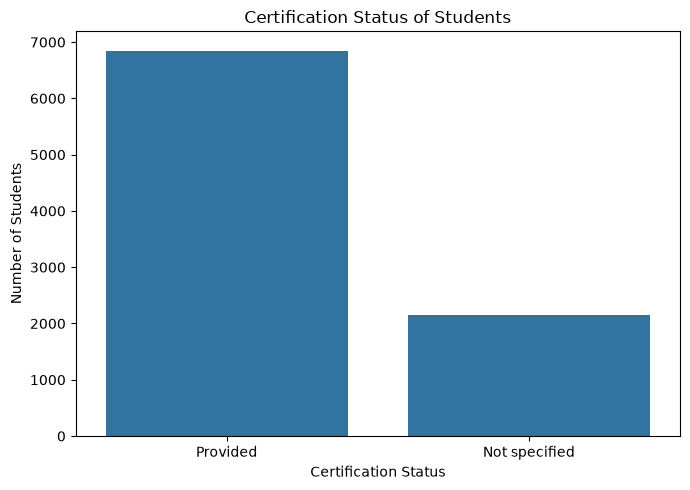

In [19]:
cert_status = career_df["Certification_Status"].value_counts()

print("Certification Status:")
display(cert_status)

plt.figure(figsize=(7, 5))

sns.barplot(
    x=cert_status.index,
    y=cert_status.values
)

plt.title("Certification Status of Students")
plt.xlabel("Certification Status")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

# CareerPath AI – Exploratory Data Analysis (EDA)

## 1. Dataset Overview
- Total records: 9,000
- Total columns: 16
- Education categories: 11
- Specialization categories: 16
- Recommended career classes: 30

## 2. Data Quality
- Missing values: 0
- Empty text values: 0
- All records contain complete processed feature values.

## 3. Education Analysis
- Class 10: 3,000 records
- Class 12: 3,000 records
- Undergraduate categories: approximately 313–363 records each.
- School-level records are more heavily represented.

## 4. Specialization Analysis
- Not yet selected: 3,000
- BiPC: 993
- MPC: 790
- Arts: 97
- Students have diverse academic backgrounds.

## 5. Career Recommendation Analysis
- 30 recommended career categories.
- Top 15 categories have relatively similar record counts.
- Career recommendations form the target variable for classification.

## 6. Academic Performance
- Average percentage: 76.83%
- Average undergraduate CGPA: 7.60
- Percentage and CGPA were analyzed separately.

## 7. Skills Analysis
- Frequently occurring technical skills include Observation, Presentation, Research methods, Python, Data analysis, SQL basics, and Microsoft Excel.
- Frequently occurring soft skills include Communication, Critical thinking, Adaptability, Teamwork, and Problem-solving.

## 8. Certification Analysis
- Provided: 6,849 (76.1%)
- Not specified: 2,151 (23.9%)
- Basic computer courses are the most common specified certification.

## 9. Conclusion
The CareerPath dataset contains diverse student profiles, academic backgrounds, skills, certifications, and recommended career pathways. EDA helped identify distributions, data quality, and important patterns that will guide feature engineering and model development.

## 10. Dataset Limitations
- The dataset may contain synthetic or rule-generated patterns.
- High model accuracy does not establish real-world career suitability.
- Some education and specialization combinations may be inconsistent.
- Certification details marked Not specified should not be interpreted as confirmed absence of certifications.
- Recommendations require real-world validation and should be treated as guidance rather than guaranteed outcomes.